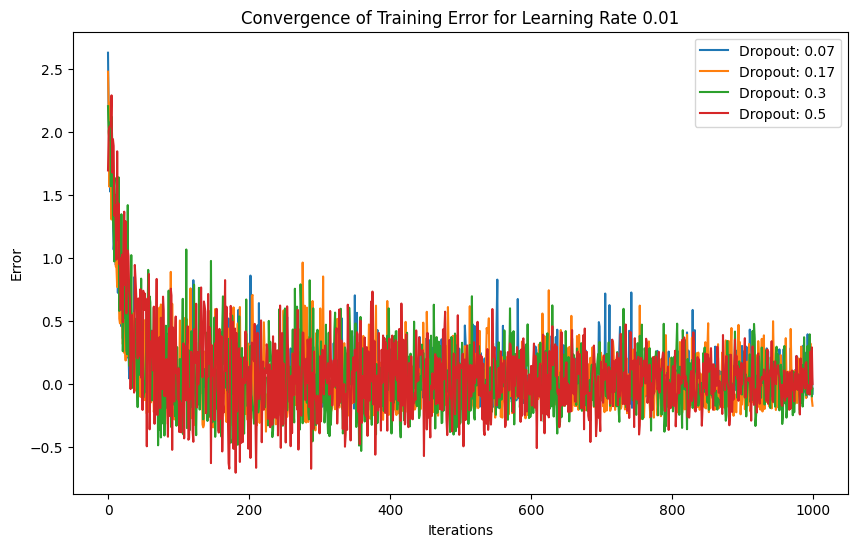

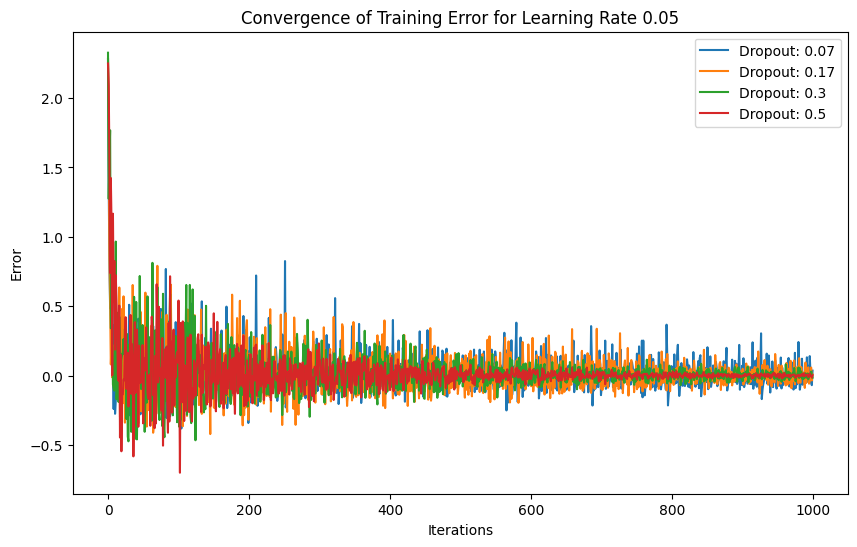

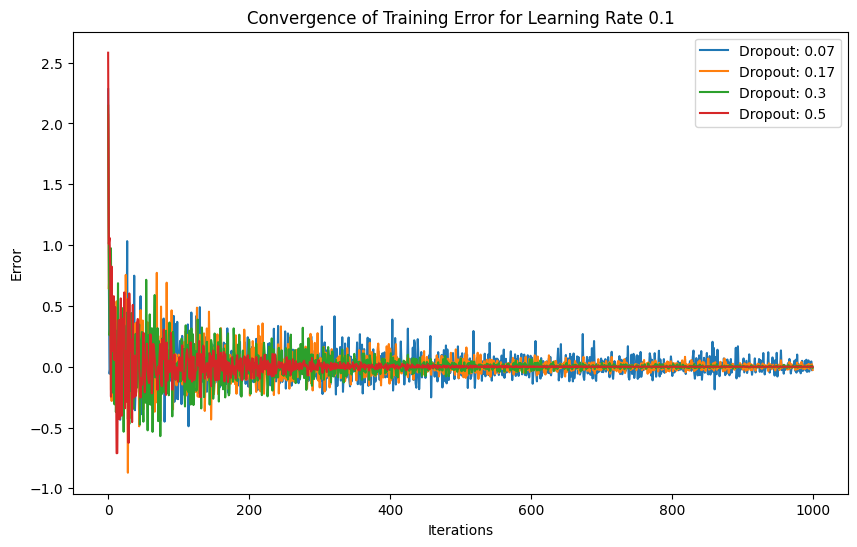

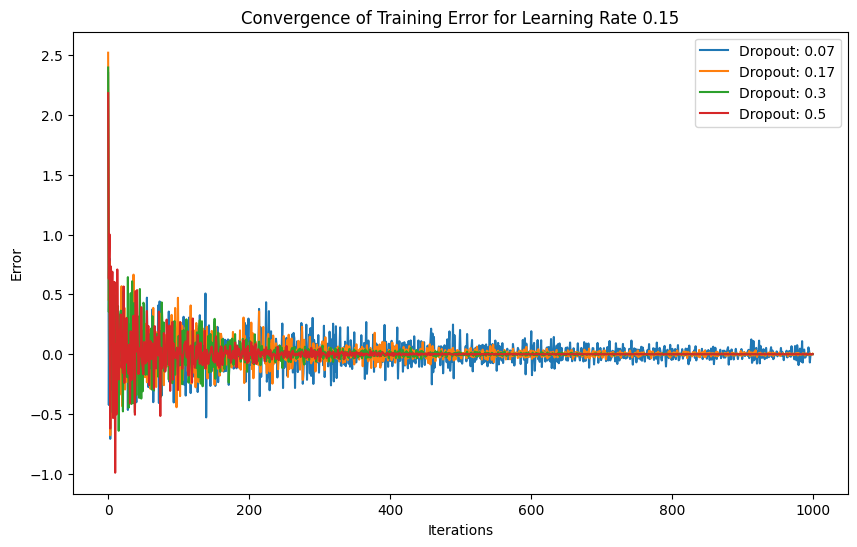

In [7]:
import numpy as np

# Sigmoid function
def logsig(x):
    return 1 / (1 + np.exp(-x))

def logsig_derivative(x):
    return logsig(x) * (1 - logsig(x))

# Linear activation
def purelin(x):
    return x

def purelin_derivative(x):
    return 1

# Dropout function
def apply_dropout(a, dropout_prob):
    mask = np.random.binomial(1, 1 - dropout_prob, size=a.shape)
    return a * mask, mask

# Initialize parameters
p = 1  
gt = 1 + np.sin((np.pi / 3) * p)  

learning_rates = [0.01, 0.05, 0.1, 0.15]

# Re-initialize the results storage
results = []

for dropout_prob in dropout_probs:
    for a in learning_rates:
        # Reset weights and biases for each learning rate and dropout probability
        W1 = W1_init.copy()
        b1 = b1_init.copy()
        W2 = W2_init.copy()
        b2 = b2_init.copy()

        # Number of iterations
        num_iterations = 1000
        errors = []

        for _ in range(num_iterations):
            # Forward pass
            n1 = np.dot(W1, [[p]]) + b1  # First layer input
            a1 = logsig(n1)  # First layer output

            # Apply dropout on hidden layer activations during training
            a1_dropout, dropout_mask = apply_dropout(a1, dropout_prob)

            n2 = np.dot(W2, a1_dropout) + b2  # Second layer input
            a2 = purelin(n2)  # Second layer output

            # Compute error
            e = gt - a2
            errors.append(e[0][0])

            # Backpropagation
            # Sensitivity of second layer
            s2 = -2 * purelin_derivative(n2) * e

            # Sensitivity of first layer
            F1_prime = np.diagflat(logsig_derivative(n1))
            s1 = np.dot(F1_prime, np.dot(W2.T, s2))

            # Apply dropout mask to sensitivity of the hidden layer
            s1 *= dropout_mask

            # Update weights and biases
            W2 -= a * np.dot(s2, a1_dropout.T)
            b2 -= a * s2

            W1 -= a * np.dot(s1, np.array([[p]]).T)
            b1 -= a * s1

        # Store the final results
        results.append({
            'dropout_prob': dropout_prob,
            'learning_rate': a,
            'W1': W1,
            'b1': b1,
            'W2': W2,
            'b2': b2,
            'errors': errors
        })

# Generate separate plots for each learning rate
for a in learning_rates:
    plt.figure(figsize=(10, 6))
    for result in results:
        if result['learning_rate'] == a:
            plt.plot(result['errors'], label=f"Dropout: {result['dropout_prob']}")
    plt.xlabel("Iterations")
    plt.ylabel("Error")
    plt.title(f"Convergence of Training Error for Learning Rate {a}")
    plt.legend()
    plt.show()

